
=== ENTRENAMIENTO AUTOMÁTICO ===
Pesos iniciales: w=[0. 0.], b=0.000

----- Época 1 -----
x=[0.0, 0.0] | z=0.000 | y_pred=1 | y_true=0 | error=-1 || w=[0. 0.] b=-0.100
x=[0.0, 1.0] | z=-0.100 | y_pred=0 | y_true=0 | error=0 || w=[0. 0.] b=-0.100
x=[1.0, 0.0] | z=-0.100 | y_pred=0 | y_true=0 | error=0 || w=[0. 0.] b=-0.100
x=[1.0, 1.0] | z=-0.100 | y_pred=0 | y_true=1 | error=1 || w=[0.1 0.1] b=0.000


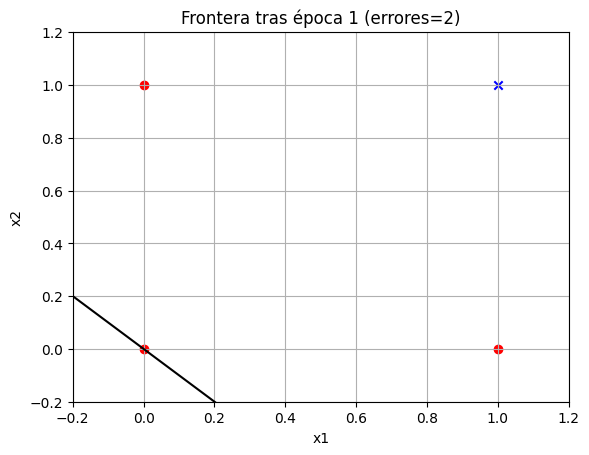


----- Época 2 -----
x=[0.0, 0.0] | z=0.000 | y_pred=1 | y_true=0 | error=-1 || w=[0.1 0.1] b=-0.100
x=[0.0, 1.0] | z=0.000 | y_pred=1 | y_true=0 | error=-1 || w=[0.1 0. ] b=-0.200
x=[1.0, 0.0] | z=-0.100 | y_pred=0 | y_true=0 | error=0 || w=[0.1 0. ] b=-0.200
x=[1.0, 1.0] | z=-0.100 | y_pred=0 | y_true=1 | error=1 || w=[0.2 0.1] b=-0.100


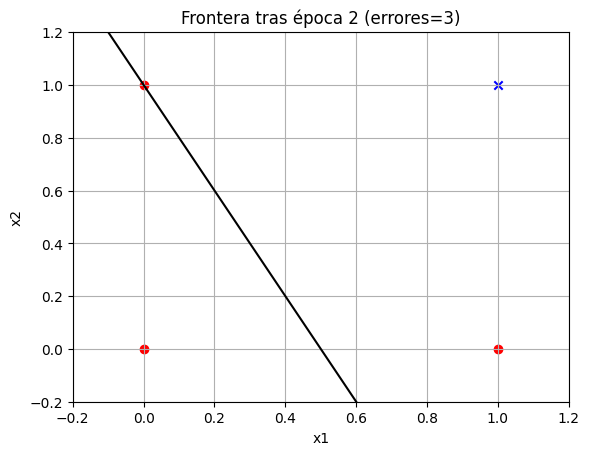


----- Época 3 -----
x=[0.0, 0.0] | z=-0.100 | y_pred=0 | y_true=0 | error=0 || w=[0.2 0.1] b=-0.100
x=[0.0, 1.0] | z=0.000 | y_pred=1 | y_true=0 | error=-1 || w=[0.2 0. ] b=-0.200
x=[1.0, 0.0] | z=0.000 | y_pred=1 | y_true=0 | error=-1 || w=[0.1 0. ] b=-0.300
x=[1.0, 1.0] | z=-0.200 | y_pred=0 | y_true=1 | error=1 || w=[0.2 0.1] b=-0.200


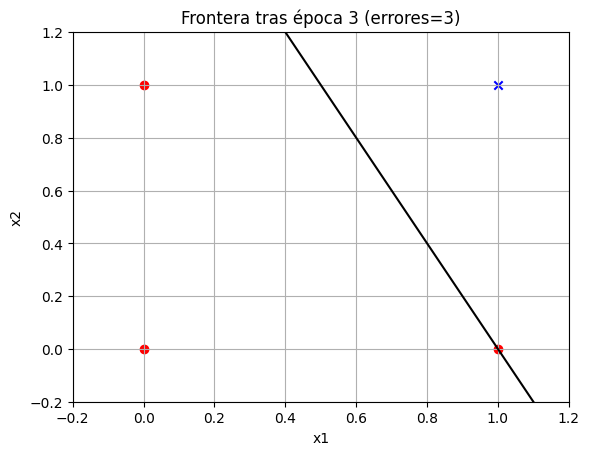


----- Época 4 -----
x=[0.0, 0.0] | z=-0.200 | y_pred=0 | y_true=0 | error=0 || w=[0.2 0.1] b=-0.200
x=[0.0, 1.0] | z=-0.100 | y_pred=0 | y_true=0 | error=0 || w=[0.2 0.1] b=-0.200
x=[1.0, 0.0] | z=-0.000 | y_pred=0 | y_true=0 | error=0 || w=[0.2 0.1] b=-0.200
x=[1.0, 1.0] | z=0.100 | y_pred=1 | y_true=1 | error=0 || w=[0.2 0.1] b=-0.200


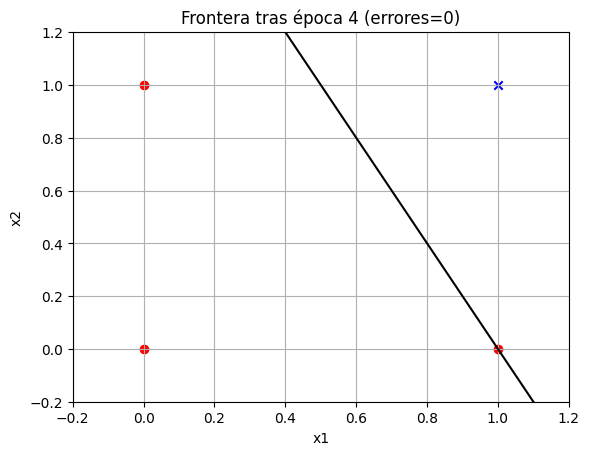

¡Sin errores! El perceptrón aprendió correctamente.


In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Función escalón: activa si z >= 0
def step(z):
    return 1 if z >= 0 else 0

# Tabla de verdad para la compuerta AND
X = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y = np.array([0,0,0,1], dtype=float)

# Clase del perceptrón
class Perceptron:
    def __init__(self, w1=0.0, w2=0.0, b=0.0, lr=0.1):  # ← ¡CORREGIDO: __init__ con doble guión!
        self.w = np.array([w1, w2], dtype=float)  # pesos
        self.b = float(b)                         # sesgo
        self.lr = float(lr)                       # learning rate

    def predict(self, x):
        z = float(np.dot(self.w, x) + self.b)
        return step(z), z

    def update(self, x, y_true):
        y_pred, z = self.predict(x)
        err = float(y_true - y_pred)
        self.w = self.w + self.lr * err * x
        self.b = self.b + self.lr * err
        return y_pred, z, err

# Dibuja puntos y línea de decisión
def plot_boundary(w, b, X, y, title=""):
    for i in range(len(X)):
        if y[i] == 0:
            plt.scatter(X[i,0], X[i,1], marker='o', color='red')
        else:
            plt.scatter(X[i,0], X[i,1], marker='x', color='blue')

    x_vals = np.linspace(-0.2, 1.2, 200)
    if abs(w[1]) > 1e-9:  # ← ¡CORREGIDO: indentación!
        y_vals = -(w[0] / w[1]) * x_vals - b / w[1]
        plt.plot(x_vals, y_vals, color='black')
    else:
        if abs(w[0]) > 1e-9:
            x_line = -b / w[0]
            plt.axvline(x_line, color='black')

    plt.xlim(-0.2, 1.2)
    plt.ylim(-0.2, 1.2)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.grid(True)
    plt.show()

# Inicializamos el perceptrón con pesos = 0
p = Perceptron(w1=0.0, w2=0.0, b=0.0, lr=0.1)

# Número de épocas
epochs = 10

print("\n=== ENTRENAMIENTO AUTOMÁTICO ===")
print(f"Pesos iniciales: w={p.w}, b={p.b:.3f}")

for epoch in range(1, epochs + 1):
    errors = 0
    print(f"\n----- Época {epoch} -----")
    for i in range(len(X)):
        y_pred, z, err = p.update(X[i], y[i])
        print(f"x={X[i].tolist()} | z={z:.3f} | y_pred={int(y_pred)} | y_true={int(y[i])} | error={int(err)} || w={p.w.round(3)} b={p.b:.3f}")
        if err != 0:
            errors += 1

    # Mostrar frontera de decisión después de cada época
    plot_boundary(p.w, p.b, X, y, f"Frontera tras época {epoch} (errores={errors})")

    # Si ya no hay errores, podemos parar temprano
    if errors == 0:
        print("¡Sin errores! El perceptrón aprendió correctamente.")
        break  # ← ¡Este 'break' ahora está bien indentado dentro del 'for'!